Number of self loop: 77307
Number of self loop: 78303
Slashdot0811: nodes=77360, edges=828161, avg clustering=0.0555
Slashdot0902: nodes=82168, edges=870161, avg clustering=0.0603


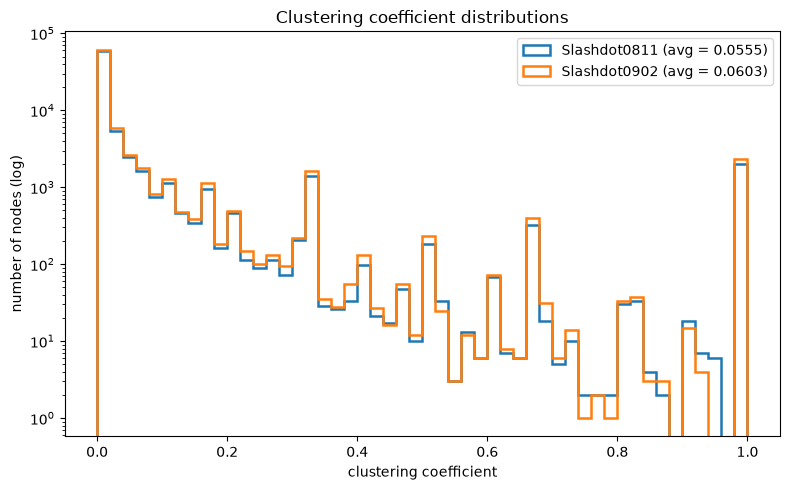

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

def load(path):
    G = nx.read_edgelist(path, comments="#", create_using=nx.DiGraph, nodetype=int)
    print("Number of self loop:", nx.number_of_selfloops(G))
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    return G

graphs = {"Slashdot0811": load("data/Slashdot0811.txt"),
          "Slashdot0902": load("data/Slashdot0902.txt")}

coeffs, averages = {}, {}
for name, G in graphs.items():
    c = nx.clustering(G.to_undirected())
    coeffs[name] = np.array(list(c.values()))
    averages[name] = coeffs[name].mean()
    print(f"{name}: nodes={G.number_of_nodes()}, edges={G.number_of_edges()}, "
          f"avg clustering={averages[name]:.4f}")

bins = np.linspace(0, 1, 51)
fig, ax = plt.subplots(figsize=(8, 5))
for (name, c), color in zip(coeffs.items(), ["tab:blue", "tab:orange"]):
    ax.hist(c, bins=bins, histtype="step", linewidth=1.8, color=color,
            label=f"{name} (avg = {averages[name]:.4f})")

ax.set_yscale("log")
ax.set_xlabel("clustering coefficient")
ax.set_ylabel("number of nodes (log)")
ax.set_title("Clustering coefficient distributions")
ax.legend()
plt.tight_layout()
plt.show()

Average degree : 21.180045759906534
Endpoints: (5, 5000) and (1000, 1)
gamma = 1.608


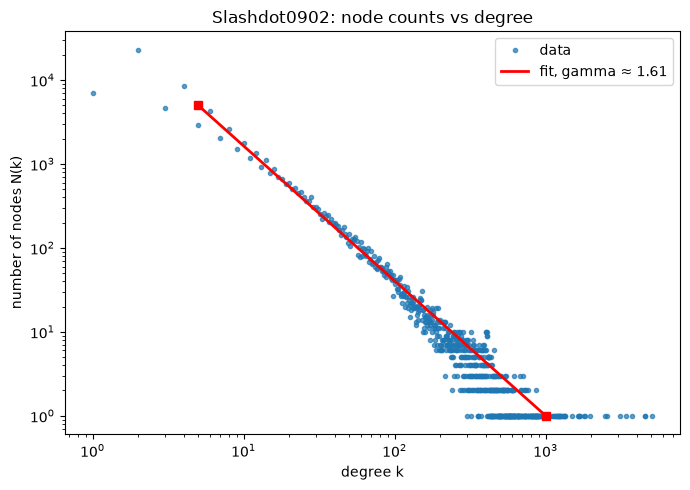

In [2]:
from collections import Counter

G = graphs["Slashdot0902"]

deg_tot = dict(G.degree())
print("Average degree :", np.mean(list(deg_tot.values())))

def plot_counts(deg, ax):
    counts = Counter(deg.values())
    counts.pop(0, None)
    k = np.array(sorted(counts))
    N = np.array([counts[x] for x in k])
    ax.loglog(k, N, "o", markersize=3, alpha=0.7, label="data")


k1, N1 = 5, 5000
k2, N2 = 1000, 1

gamma = np.log(N1 / N2) / np.log(k2 / k1)
print(f"Endpoints: ({k1}, {N1}) and ({k2}, {N2})")
print(f"gamma = {gamma:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
plot_counts(deg_tot, ax)
ax.loglog([k1, k2], [N1, N2], "r-", linewidth=2,
          label=f"fit, gamma ≈ {gamma:.2f}")
ax.plot([k1, k2], [N1, N2], "rs", markersize=6)
ax.set_xlabel("degree k")
ax.set_ylabel("number of nodes N(k)")
ax.set_title("Slashdot0902: node counts vs degree")
ax.legend()
plt.tight_layout()
plt.show()

Average degree : 21.410573940020683
Endpoints: (5, 5000) and (800, 1)
gamma = 1.678


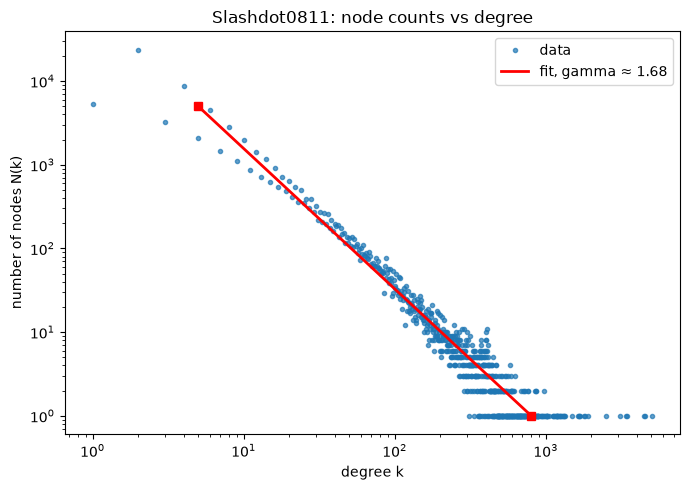

In [3]:
from collections import Counter

G = graphs["Slashdot0811"]

deg_tot = dict(G.degree())
print("Average degree :", np.mean(list(deg_tot.values())))

def plot_counts(deg, ax):
    counts = Counter(deg.values())
    counts.pop(0, None)
    k = np.array(sorted(counts))
    N = np.array([counts[x] for x in k])
    ax.loglog(k, N, "o", markersize=3, alpha=0.7, label="data")


k1, N1 = 5, 5000
k2, N2 = 800, 1

gamma = np.log(N1 / N2) / np.log(k2 / k1)
print(f"Endpoints: ({k1}, {N1}) and ({k2}, {N2})")
print(f"gamma = {gamma:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
plot_counts(deg_tot, ax)
ax.loglog([k1, k2], [N1, N2], "r-", linewidth=2,
          label=f"fit, gamma ≈ {gamma:.2f}")
ax.plot([k1, k2], [N1, N2], "rs", markersize=6)
ax.set_xlabel("degree k")
ax.set_ylabel("number of nodes N(k)")
ax.set_title("Slashdot0811: node counts vs degree")
ax.legend()
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd


G = graphs["Slashdot0902"]
df = pd.DataFrame({"in": dict(G.in_degree()),
                   "out": dict(G.out_degree())})
df.head()

,in,out
0,240,215
1,163,166
2,20,0
3,59,54
4,125,110


In [5]:
# Method 1: top 5% nodes with largest in or out degree 
q = 0.95

in_degree_threshold = df["in"].quantile(q)
out_degree_threshold = df["out"].quantile(q)

in_degree_pct_rank = df["in"].rank(pct=True)
out_degree_pct_rank = df["out"].rank(pct=True)

is_high_in_degree = df["in"] >= in_degree_threshold
is_high_out_degree = df["out"] >= out_degree_threshold

df["Method 1"] = "regular"
df.loc[is_high_in_degree & ~is_high_out_degree, "Method 1"] = "prestigious"
df.loc[is_high_out_degree & ~is_high_in_degree, "Method 1"] = "gregarious"

# Nodes in the top 5% for both: assign by whichever percentile rank is higher
is_high_in_and_out = is_high_in_degree & is_high_out_degree
df.loc[is_high_in_and_out & (in_degree_pct_rank >= out_degree_pct_rank), "Method 1"] = "prestigious"
df.loc[is_high_in_and_out & (in_degree_pct_rank < out_degree_pct_rank), "Method 1"] = "gregarious"

print(f"Method 1 thresholds")
print(f"- pretigious: in_degree >= {in_degree_threshold}")
print(f"- gregarious: out_degree >= {out_degree_threshold}")
print(df["Method 1"].value_counts())
print("-----------------------------------------------------------")

# Method 2: top 5% nodes with largest/smallest in/out degree log ratio (only consider nodes with total degree >= 10)
log_ratio = np.log((df["in"] + 1) / (df["out"] + 1))
active = (df["in"] + df["out"]) >= 10

q = 0.95
high_ratio_threshold = log_ratio[active].quantile(q)
low_ratio_threshold = log_ratio[active].quantile(1-q)

df["Method 2"] = "regular"
df.loc[active & (log_ratio >= high_ratio_threshold), "Method 2"] = "prestigious"
df.loc[active & (log_ratio <= low_ratio_threshold), "Method 2"] = "gregarious"

print(f"Method 2 thresholds:")
print(f"- pretigious: log_ratio >= {high_ratio_threshold:.3f} (in/out ≈ {np.exp(high_ratio_threshold):.2f})")
print(f"- gregarious: log_ratio <= {low_ratio_threshold:.3f} (in/out ≈ {np.exp(low_ratio_threshold):.2f})")
print(df["Method 2"].value_counts())


Method 1 thresholds
- pretigious: in_degree >= 43.0
- gregarious: out_degree >= 44.0
Method 1
regular        77463
prestigious     2953
gregarious      1752
Name: count, dtype: int64
-----------------------------------------------------------
Method 2 thresholds:
- pretigious: log_ratio >= 0.629 (in/out ≈ 1.88)
- gregarious: log_ratio <= -0.621 (in/out ≈ 0.54)
Method 2
regular        79601
prestigious     1286
gregarious      1281
Name: count, dtype: int64


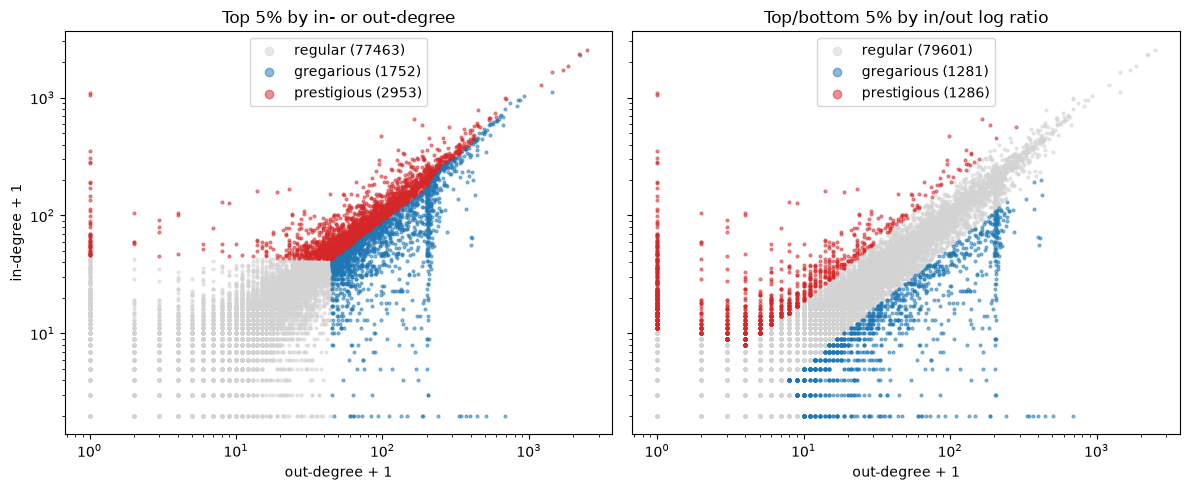

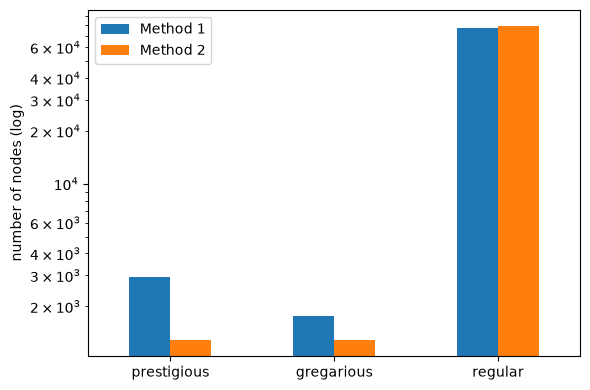

In [6]:
CLASS_COLORS = {"prestigious": "tab:red", "gregarious": "tab:blue", "regular": "lightgray"}
CLASS_ORDER = ["prestigious", "gregarious", "regular"]
METHOD_COLUMNS = ["Method 1", "Method 2"]
METHOD_TITLES = [
    "Top 5% by in- or out-degree",
    "Top/bottom 5% by in/out log ratio",
]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, method_column, method_title in zip(axes, METHOD_COLUMNS, METHOD_TITLES):
    for node_class in ["regular", "gregarious", "prestigious"]:  # regular drawn first, so it sits underneath
        class_nodes = df[df[method_column] == node_class]
        ax.scatter(
            class_nodes["out"] + 1,
            class_nodes["in"] + 1,
            s=4,
            alpha=0.5,
            color=CLASS_COLORS[node_class],
            label=f"{node_class} ({len(class_nodes)})",
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("out-degree + 1")
    ax.set_title(method_title)
    ax.legend(markerscale=3)
axes[0].set_ylabel("in-degree + 1")
plt.tight_layout()
plt.show()

class_counts_by_method = pd.DataFrame(
    {method_column: df[method_column].value_counts() for method_column in METHOD_COLUMNS}
).loc[CLASS_ORDER]
class_counts_by_method.plot.bar(logy=True, figsize=(6, 4), rot=0)
plt.ylabel("number of nodes (log)")
plt.tight_layout()
plt.show()